## Question 3 

In [1]:
from pathlib import Path, PurePosixPath
import zipfile
import pandas as pd

zip_path = Path(
    r"C:\Users\Tbose\Downloads\Project 1 Required Resources-20261102\research_corpus.zip"
)

with zipfile.ZipFile(zip_path, "r") as archive:
    text_files = sorted(
        name for name in archive.namelist()
        if name.lower().endswith(".txt")
    )

    articles = []
    for name in text_files:
        content = archive.read(name).decode("utf-8", errors="replace")
        articles.append({
            "article_id": PurePosixPath(name).stem,
            "filename": name,
            "content": content,
        })

articles_df = pd.DataFrame(articles)

print("Articles loaded:", len(articles_df))
print("Dataframe shape:", articles_df.shape)
display(articles_df[["article_id", "filename"]])
print("\nFirst article preview:")
print(articles_df.loc[0, "content"][:500])

Articles loaded: 5
Dataframe shape: (5, 3)


,article_id,filename
0,research_1,research_corpus/research_1.txt
1,research_2,research_corpus/research_2.txt
2,research_3,research_corpus/research_3.txt
3,research_4,research_corpus/research_4.txt
4,research_5,research_corpus/research_5.txt



First article preview:
The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitat


In [2]:
# 3.2
import re
import unicodedata
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download("punkt", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("punkt_tab", quiet=True)

stop_words = set(stopwords.words("english"))

def denoise_layout(text):
    text = unicodedata.normalize("NFKC", str(text))
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]", " ", text)
    text = re.sub(r"(?im)^[ \t]*(?:page[ \t]*)?\d+[ \t]*\n?", "", text)
    text = re.sub(r"(?<=\w)-[ \t]*\n[ \t]*(?=[a-z])", "", text)
    text = re.sub(r"(?<!\n)\n(?!\n)", " ", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r" *\n *", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

def prepare_tokens(text):
    words = word_tokenize(text.lower())
    return [
        word for word in words
        if word.isalpha() and word not in stop_words
    ]

articles_df["denoised_content"] = articles_df["content"].apply(denoise_layout)
articles_df["tokens"] = articles_df["denoised_content"].apply(prepare_tokens)
articles_df["preprocessed_content"] = articles_df["tokens"].apply(" ".join)

print("Articles processed:", len(articles_df))
display(
    articles_df.assign(
        token_count=articles_df["tokens"].apply(len)
    )[["article_id", "token_count"]]
)
print("\nFirst article token preview:")
print(articles_df.loc[0, "tokens"][:40])

Articles processed: 5


,article_id,token_count
0,research_1,3112
1,research_2,1249
2,research_3,2107
3,research_4,3184
4,research_5,2246



First article token preview:
['purposes', 'article', 'position', 'mixed', 'methods', 'research', 'mixed', 'research', 'synonym', 'natural', 'complement', 'traditional', 'qualitative', 'quantitative', 'research', 'present', 'pragmatism', 'offering', 'attractive', 'philosophical', 'partner', 'mixed', 'methods', 'research', 'provide', 'framework', 'designing', 'conducting', 'mixed', 'methods', 'research', 'briefly', 'review', 'paradigm', 'wars', 'incompatibility', 'thesis', 'show', 'commonalities', 'quantitative']


TextRank extractive summary:
Our purpose in writing this article is to present mixed methods research as the third research paradigm in educational research.5 We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful. Mixed methods research as the third research paradigm can also help bridge the schism between quantitative and qualitative research (Onwuegbuzie & Leech, 2004a). For example, qualitative researchers should be free to use quantitative methods, and quantitative researchers should be free to use qualitative methods. We contend that epistemological and paradigmatic ecumenicalism is within reach in the research paradigm of mixed methods research. The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present p

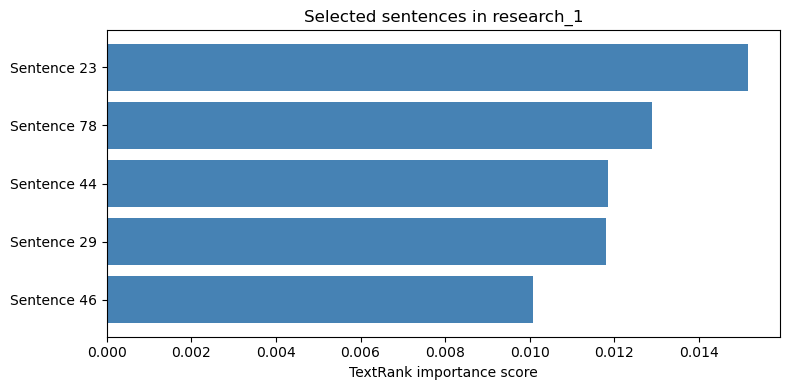

In [4]:
# 3.3
import numpy as np
import matplotlib.pyplot as plt
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

first_article = articles_df.loc[0, "denoised_content"]

sentences = [
    sentence.strip()
    for sentence in sent_tokenize(first_article)
    if len(sentence.split()) > 4
]

vectorizer = TfidfVectorizer(stop_words="english")
sentence_vectors = vectorizer.fit_transform(sentences)
similarity = cosine_similarity(sentence_vectors)

# Sentence-similarity graph
np.fill_diagonal(similarity, 0)
row_sums = similarity.sum(axis=1, keepdims=True)

transition = np.divide(
    similarity,
    row_sums,
    out=np.zeros_like(similarity),
    where=row_sums != 0,
)


dangling_rows = np.where(row_sums.ravel() == 0)[0]
transition[dangling_rows, :] = 1 / len(sentences)

# TextRank sentence scores
scores = np.full(len(sentences), 1 / len(sentences))
damping = 0.85

for _ in range(100):
    updated_scores = (
        (1 - damping) / len(sentences)
        + damping * transition.T.dot(scores)
    )

    if np.allclose(scores, updated_scores, atol=1e-6):
        scores = updated_scores
        break

    scores = updated_scores

# Highest-ranked sentences
ranked_indices = np.argsort(scores)[::-1]
selected_indices = []
similarity_threshold = 0.65

for index in ranked_indices:
    if all(
        similarity[index, selected] < similarity_threshold
        for selected in selected_indices
    ):
        selected_indices.append(int(index))

    if len(selected_indices) == 5:
        break


summary_indices = sorted(selected_indices)
first_article_summary = " ".join(
    sentences[index] for index in summary_indices
)

print("TextRank extractive summary:")
print(first_article_summary)
print(f"\nOriginal words: {len(first_article.split())}")
print(f"Summary words: {len(first_article_summary.split())}")
print(f"Unique sentences selected: {len(summary_indices)}")

# Visualize the selected sentences' TextRank scores
plot_indices = sorted(selected_indices, key=lambda index: scores[index])

plt.figure(figsize=(8, 4))
plt.barh(
    [f"Sentence {index + 1}" for index in plot_indices],
    [scores[index] for index in plot_indices],
    color="steelblue",
)
plt.xlabel("TextRank importance score")
plt.title("Selected sentences in research_1")
plt.tight_layout()
plt.show()

Aggregate TF-IDF extractive summary:

[research_2] These positions of the researcher may impact the research in three major ways.

[research_2] Women to whom I reached out to share with me their experiences were very receptive and cooperative.

[research_3] The focus is no longer only on production, or even on both planning and production.

[research_3] In this respect, it is similar to other methodologies such as action research.

[research_4] The most common descriptors were (separately or together) reliability or internal consistency.

[research_4] The authors provided information on how they understood each of these aspects.

[research_5] Rather, the persons with the best skills should be closest to the data.

[research_5] It would be impossible to remove all bias because one is a human being.


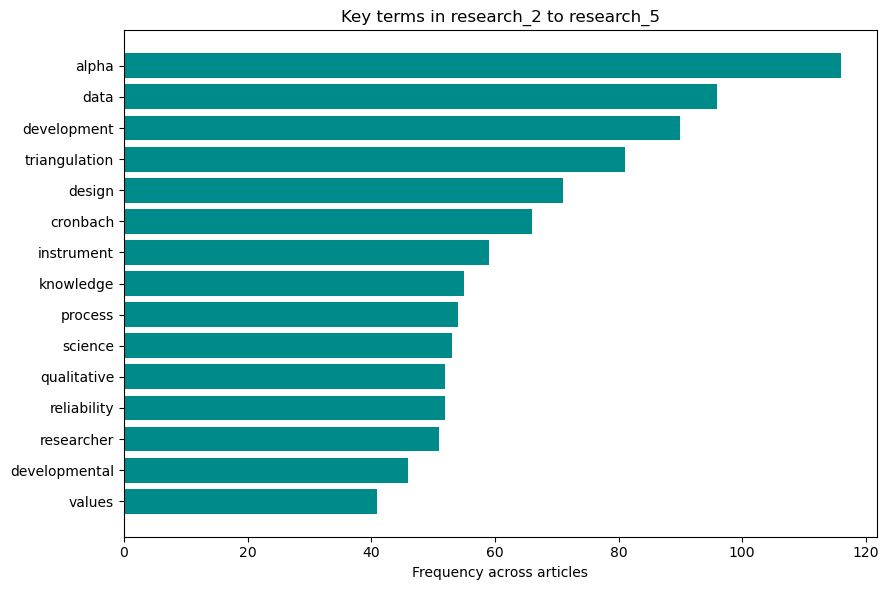


Sentences in aggregate summary: 8


In [7]:
#3.4
import re
from collections import Counter

import matplotlib.pyplot as plt
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer

remaining_articles = articles_df.iloc[1:].copy()

def is_complete_sentence(sentence):
    sentence = sentence.strip()
    word_count = len(sentence.split())

    ends_with_punctuation = bool(
        re.search(r'[.!?]["’”\')\]]*$', sentence)
    )
    balanced_parentheses = sentence.count("(") == sentence.count(")")
    balanced_brackets = sentence.count("[") == sentence.count("]")

    return (
        12 <= word_count <= 45
        and sentence[:1].isupper()
        and ends_with_punctuation
        and balanced_parentheses
        and balanced_brackets
    )

sentence_records = []

for _, row in remaining_articles.iterrows():
    for sentence_number, sentence in enumerate(
        sent_tokenize(row["denoised_content"])
    ):
        sentence = sentence.strip()
        if is_complete_sentence(sentence):
            sentence_records.append({
                "article_id": row["article_id"],
                "sentence_number": sentence_number,
                "sentence": sentence,
            })

if not sentence_records:
    raise ValueError("No complete sentences passed the filters.")

sentences_3_4 = [record["sentence"] for record in sentence_records]

tfidf_vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
)
sentence_matrix = tfidf_vectorizer.fit_transform(sentences_3_4)

sentence_scores = []
for row_number in range(sentence_matrix.shape[0]):
    row = sentence_matrix.getrow(row_number)
    sentence_scores.append(row.data.mean() if row.nnz else 0)

# Two high-ranking, non-redundant sentences per article
aggregate_summary = []

for article_id in remaining_articles["article_id"]:
    candidate_indices = [
        i for i, record in enumerate(sentence_records)
        if record["article_id"] == article_id
    ]
    candidate_indices.sort(
        key=lambda i: sentence_scores[i],
        reverse=True,
    )

    selected_for_article = []

    for index in candidate_indices:
        is_redundant = any(
            sentence_matrix[index]
            .multiply(sentence_matrix[selected])
            .sum() >= 0.55
            for selected in selected_for_article
        )

        if not is_redundant:
            selected_for_article.append(index)

        if len(selected_for_article) == 2:
            break

    for index in sorted(
        selected_for_article,
        key=lambda i: sentence_records[i]["sentence_number"],
    ):
        aggregate_summary.append(sentence_records[index])

print("Aggregate TF-IDF extractive summary:")
for record in aggregate_summary:
    print(f"\n[{record['article_id']}] {record['sentence']}")

generic_terms = {
    "research", "study", "article", "one", "use", "using",
    "also", "however", "result", "results",
}
term_counts = Counter(
    token
    for tokens in remaining_articles["tokens"]
    for token in tokens
    if token not in generic_terms
)

top_terms = term_counts.most_common(15)

if top_terms:
    terms = [term for term, _ in top_terms][::-1]
    counts = [count for _, count in top_terms][::-1]

    plt.figure(figsize=(9, 6))
    plt.barh(terms, counts, color="darkcyan")
    plt.xlabel("Frequency across articles")
    plt.title("Key terms in research_2 to research_5")
    plt.tight_layout()
    plt.show()

print(f"\nSentences in aggregate summary: {len(aggregate_summary)}")

## Question 4 

Topic 1: alpha, cronbach, instrument, science, reliability, education, items, authors, scales, internal
Topic 2: triangulation, development, design, researcher, developmental, instructional, reflexivity, denzin, fusch, researchers
Topic 3: methods, mixed, researchers, quantitative, purists, paradigm, reality, educational, many, paradigms

Topic distribution by article:


,article_id,Topic 1,Topic 2,Topic 3
0,research_1,0.000,0.000,1.000
1,research_2,0.001,0.999,0.001
2,research_3,0.000,0.999,0.000
3,research_4,1.000,0.000,0.000
4,research_5,0.000,0.999,0.000


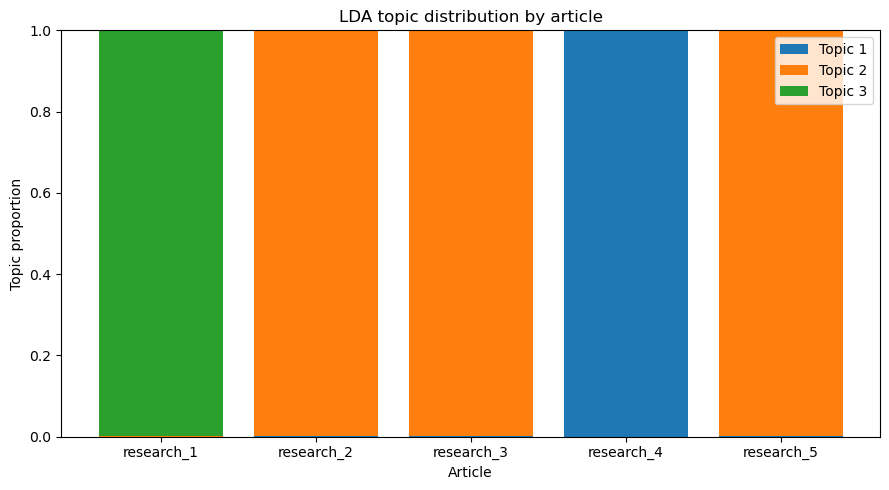

In [8]:
#4.1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

n_topics = 3


count_vectorizer = CountVectorizer(
    max_features=1000,
    max_df=0.95,
    min_df=1,
)

document_term_matrix = count_vectorizer.fit_transform(
    articles_df["preprocessed_content"]
)

lda_model = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42,
    learning_method="batch",
    max_iter=20,
)

document_topic_distribution = lda_model.fit_transform(document_term_matrix)
feature_names = count_vectorizer.get_feature_names_out()

# Top words for each topic
for topic_number, topic_weights in enumerate(lda_model.components_, start=1):
    top_word_indices = topic_weights.argsort()[::-1][:10]
    top_words = [feature_names[i] for i in top_word_indices]
    print(f"Topic {topic_number}: {', '.join(top_words)}")

# Each article's topic proportions
topic_columns = [f"Topic {i}" for i in range(1, n_topics + 1)]
topic_distribution_df = pd.DataFrame(
    document_topic_distribution,
    columns=topic_columns,
)
topic_distribution_df.insert(0, "article_id", articles_df["article_id"].values)

print("\nTopic distribution by article:")
display(topic_distribution_df.round(3))

# Topic proportions as a stacked bar chart
x = np.arange(len(articles_df))
bottom = np.zeros(len(articles_df))

plt.figure(figsize=(9, 5))
for topic_index in range(n_topics):
    values = document_topic_distribution[:, topic_index]
    plt.bar(
        x,
        values,
        bottom=bottom,
        label=f"Topic {topic_index + 1}",
    )
    bottom += values

plt.xticks(x, articles_df["article_id"], rotation=0)
plt.ylabel("Topic proportion")
plt.xlabel("Article")
plt.title("LDA topic distribution by article")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
#4.2
from pathlib import Path
import pyLDAvis
import pyLDAvis.lda_model
from IPython.display import display

lda_visualization = pyLDAvis.lda_model.prepare(
    lda_model,
    document_term_matrix,
    count_vectorizer,
)

display(pyLDAvis.display(lda_visualization))

output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

html_path = output_folder / "lda_intertopic_distance.html"
pyLDAvis.save_html(lda_visualization, str(html_path))

print(f"Interactive map saved to: {html_path.resolve()}")

Interactive map saved to: C:\Users\Tbose\outputs\lda_intertopic_distance.html
